In [1]:
# Install CloudDrift
!pip install -q "zarr<3" "xarray==2025.1.2" clouddrift

# Install Cartopy
!pip install -q cartopy

In [2]:
# Import required libraries
import clouddrift as cd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import seaborn as sns
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import re

from clouddrift.datasets import gdp6h
from clouddrift.ragged import subset
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import matplotlib.patheffects as pe
from matplotlib.patches import Circle
from sklearn.model_selection import train_test_split, KFold

# Load the 6 hourly Global Drifter Program dataset
ds = gdp6h()
ds

<xarray.Dataset> Size: 2GB
Dimensions:                (traj: 28706, obs: 48840300)
Coordinates:
    id                     (traj) int64 230kB ...
    time                   (obs) datetime64[ns] 391MB ...
Dimensions without coordinates: traj, obs
Data variables: (12/48)
    BuoyTypeManufacturer   (traj) <U20 2MB ...
    BuoyTypeSensorArray    (traj) <U20 2MB ...
    CurrentProgram         (traj) float64 230kB ...
    DeployingCountry       (traj) <U20 2MB ...
    DeployingShip          (traj) <U20 2MB ...
    DeploymentComments     (traj) <U20 2MB ...
    ...                     ...
    start_lon              (traj) float32 115kB ...
    temp                   (obs) float32 195MB ...
    typebuoy               (traj) |S10 287kB ...
    typedeath              (traj) int8 29kB ...
    ve                     (obs) float32 195MB ...
    vn                     (obs) float32 195MB ...
Attributes: (12/18)
    Conventions:          CF-1.6
    acknowledgement:      Lumpkin, Rick; Centurioni, Luca (2019). NOAA Global...
    contributor_name:     NOAA Global Drifter Program
    contributor_role:     Data Acquisition Center
    date_created:         2025-07-14T15:15:03.441003
    doi:                  10.25921/7ntx-z961
    ...                   ...
    publisher_name:       GDP Drifter DAC
    publisher_url:        https://www.aoml.noaa.gov/phod/gdp
    summary:              Global Drifter Program six-hourly data
    time_coverage_end:    2025-01-20:00:00:00Z
    time_coverage_start:  1979-02-15:00:00:00Z
    title:                Global Drifter Program drifting buoy collection

In [3]:
# LAT and LON of full North Atlantic Ocean Basin
LAT_MIN, LAT_MAX = 10.0, 45.0
LON_MIN, LON_MAX = -80.0, -20.0
region_name = "North Atlantic Ocean Basin"

In [4]:
# ==========================================
# DATA WRANGLING
# ==========================================

# ------------------------------------------------------------------
# Get observations within our region
# ------------------------------------------------------------------

# Extract lats and lons
lats = ds['lat'].values
lons = ((ds['lon'].values + 180) % 360) - 180

# Get observation within required region
mask = ((lats >= LAT_MIN) & (lats < LAT_MAX) &
       (lons >= LON_MIN) & (lons < LON_MAX))

# ------------------------------------------------------------------
# Give every observation its drifter id (id and rowsize are per trajectory)
# ------------------------------------------------------------------

# Duplicates each ID by its corresponding 'rowsize' count
obs_ids = np.repeat(ds['id'].values, ds['rowsize'].values)
assert len(obs_ids) == ds.sizes['obs'], "rowsize does not add up to the number of observations"

# ------------------------------------------------------------------
# Filter the data and build the dataframe
# ------------------------------------------------------------------

# Slice the arrays using the boolean mask to filter all 8 core variables
filtered_lats = lats[mask]
filtered_lons = lons[mask]
filtered_ids = obs_ids[mask]
filtered_times = ds['time'].values[mask]
filtered_ve = ds['ve'].values[mask]
filtered_vn = ds['vn'].values[mask]
filtered_temp = ds['temp'].values[mask]
filtered_drogue = ds['drogue_status'].values[mask]

# Build the DataFrame
df = pd.DataFrame({
    'id': filtered_ids,
    'time': filtered_times,
    'lat': filtered_lats,
    'lon': filtered_lons,
    've': filtered_ve,
    'vn': filtered_vn,
    'temp': filtered_temp,
    'drogue_status': filtered_drogue
})

# Sorting by id and then by time (using stable sort)
df = df.sort_values(by=['id', 'time'], kind='stable').reset_index(drop=True)

# ------------------------------------------------------------------
# Observation count and timespan
# ------------------------------------------------------------------
print(f"Number of Observations: {len(df):,}")
print(f"Number of drifters: {df['id'].nunique():,}")
print(f"{df['time'].min():%Y-%m-%d} to {df['time'].max():%Y-%m-%d}")

Number of Observations: 6,116,067
Number of drifters: 3,896
1989-10-31 to 2025-01-20


In [5]:
# ==================================================================
# 5-FOLD CROSS-VALIDATION SPLITTER SETUP
# ==================================================================

# Set random seed for reproducibility
SEED = 42
K = 5

# ------------------------------------------------------------------
# Split unique drifter IDs into 80% train and 20% test sets
# ------------------------------------------------------------------
all_ids = df['id'].unique()  # Get all drifter identification numbers
kf = KFold(n_splits=K, shuffle=True, random_state=SEED)

print(f"Total unique drifters across dataset: {len(all_ids):,}")
print(f"Ready to run {K}-Fold Cross-Validation loop.")

# Storing the folds as {fold number: (training drifter ids, test drifter ids)}
folds = {fold: (all_ids[tr], all_ids[te]) for fold, (tr, te) in enumerate(kf.split(all_ids), start=1)}
print()

# Printing fold details
for fold, (tr_ids, te_ids) in folds.items():
    print(f"Fold {fold}: {len(tr_ids):,} train / {len(te_ids):,} test drifters | "
          f"{df['id'].isin(tr_ids).sum():,} train / {df['id'].isin(te_ids).sum():,} test observations")

Total unique drifters across dataset: 3,896
Ready to run 5-Fold Cross-Validation loop.

Fold 1: 3,116 train / 780 test drifters | 4,982,840 train / 1,133,227 test observations
Fold 2: 3,117 train / 779 test drifters | 4,824,114 train / 1,291,953 test observations
Fold 3: 3,117 train / 779 test drifters | 4,904,746 train / 1,211,321 test observations
Fold 4: 3,117 train / 779 test drifters | 4,851,922 train / 1,264,145 test observations
Fold 5: 3,117 train / 779 test drifters | 4,900,646 train / 1,215,421 test observations


In [6]:
# ==================================================================
# LINEAR REGRESSION MODEL: SETTINGS AND CUSTOMISATION
# ==================================================================

# N_STEPS = how many 6-hour steps ahead the model forecasts.
N_STEPS = 40
HORIZON_HOURS = 6 * N_STEPS

# ------------------------------------------------------------------
# INDEPENDENT VARIABLES
# ------------------------------------------------------------------
# FEATURES is the list of independent variables
# The dependent variable (Y) is fixed: the displacement of the drifter over the
# horizon, as two numbers, in km:
#    dx_km = eastward displacement,   dy_km = northward displacement.
#
# Variables used in the model are as follows
#   'lat', 'lon'            position of the drifter at time t (degrees)
#   'dx_lag1', 'dy_lag1'    LAGGED DISPLACEMENTS: the east / north displacement over the 6 hours
#                           before time t (lag1), the 6 hours before that (lag2), and so on. These
#                           are always counted in 6-hour steps, whatever N_STEPS is

FEATURES = ['lat', 'lon', 'dx_lag1', 'dy_lag1']

def add_external_variables(d):
    """
    Hook for adding variables that are not in df.
    Input: d is one table of observations with the
    columns id, time, lat, lon, ve, vn, temp, drogue_status (sorted by id, then time).
    Add new columns to d and return it. By default nothing is added.

    Example for wind (lookup_wind is a function you would write or load yourself):
        d['wind_u'], d['wind_v'] = lookup_wind(d['time'], d['lat'], d['lon'])
    Use only information that would be known at the time of the forecast.
    """

    return d

# ------------------------------------------------------------------
# Same 0.1 degree grid as the Markov chain
# ------------------------------------------------------------------
CELL = 0.1
N_LAT = int(round((LAT_MAX - LAT_MIN) / CELL))   # 350 rows
N_LON = int(round((LON_MAX - LON_MIN) / CELL))   # 600 columns
N_STATES = N_LAT * N_LON                         # 210,000 cells

def to_state(lat, lon):
    """Lat/lon -> cell number (identical to the Markov chain's to_state)."""
    lat_idx = np.floor((LAT_MAX - np.asarray(lat)) / CELL).astype(np.int64)
    lon_idx = np.floor((np.asarray(lon) - LON_MIN) / CELL).astype(np.int64)
    lat_idx = np.clip(lat_idx, 0, N_LAT - 1)
    lon_idx = np.clip(lon_idx, 0, N_LON - 1)
    return lat_idx * N_LON + lon_idx

def state_to_latlon(state):
    """Cell number -> lat/lon of the cell centre (identical to the Markov chain's)."""
    state = np.asarray(state)
    lat = LAT_MAX - (state // N_LON + 0.5) * CELL
    lon = LON_MIN + (state % N_LON + 0.5) * CELL
    return lat, lon

# ------------------------------------------------------------------
# Constants
# ------------------------------------------------------------------
# Kilometres in one degree of latitude
KM_PER_DEG = 6371.0 * np.pi / 180
# The data's time step: observations exactly 6 hours apart are consecutive.
STEP = np.timedelta64(6, 'h')
# The two dependent variables (columns of the table built in the next cell).
TARGETS = ['dx_km', 'dy_km']
# Same epsilon as the Markov chain evaluation, for flooring tiny probabilities.
EPS = 1e-5
# Seasons used by the 'quarter' column: month -> quarter, and the quarter labels
QUARTER_OF_MONTH = {3: 1, 4: 1, 5: 1, 6: 2, 7: 2, 8: 2, 9: 3, 10: 3, 11: 3, 12: 4, 1: 4, 2: 4}
quarter_names = {1: 'Mar-May', 2: 'Jun-Aug', 3: 'Sep-Nov', 4: 'Dec-Feb'}

In [7]:
# ==================================================================
# BUILD THE TABLE OF FORECAST WINDOWS (dependent variable + features)
# ==================================================================
def prepare_frame(frame):
    """Put one table of observations in track order and work out, for every observation, the
    things the model needs (displacements, quarter, and which observations are joined by an
    unbroken run of 6-hourly data). Returns them in a dictionary."""

    # Drop rows with missing id/time/position and put every drifter's track in time order
    d = (frame.dropna(subset=['id', 'time', 'lat', 'lon'])
              .sort_values(['id', 'time'], kind='stable').reset_index(drop=True))


    n = len(d)
    ids = d['id'].to_numpy()
    t = d['time'].to_numpy()
    lat = d['lat'].to_numpy(dtype=float)
    lon = d['lon'].to_numpy(dtype=float)

    # consecutive(k)[i] is True when there is an unbroken 6-hourly track between them.
    _cache = {}
    def consecutive(k):
        if k not in _cache:
            ok = np.zeros(n, dtype=bool)
            if 0 < k < n:
                # Checks that the ids are the same and that they are k * 6 hours apart
                ok[k:] = (ids[k:] == ids[:-k]) & ((t[k:] - t[:-k]) == k * STEP)
            _cache[k] = ok
        return _cache[k]

    def lagged(x, k):
        """Value of x for the observation k steps earlier (NaN if the track is broken)."""
        x = np.asarray(x, dtype=float)
        if k == 0:
            return x

        out = np.full(n, np.nan)
        if 0 < k < n:
            # Out [k:] all obs from k to the end
            out[k:] = np.where(consecutive(k)[k:], x[:-k], np.nan)
        return out

    # --------------------------------------------------------------
    # Displacements, in km
    # --------------------------------------------------------------
    def forward(k):
        """Where each observation is k steps (k x 6 hours) later, and the displacement to get there.
        has[i] is True if observation i is followed by an unbroken run of 6-hourly observations
        of the same drifter up to k steps later."""
        has = np.zeros(n, dtype=bool)
        la = np.full(n, np.nan)
        lo = np.full(n, np.nan)
        if 0 < k < n:
            has[:n - k] = consecutive(k)[k:]
            la[:n - k] = np.where(has[:n - k], lat[k:], np.nan)
            lo[:n - k] = np.where(has[:n - k], lon[k:], np.nan)
        # Degrees -> km
        dy_ = (la - lat) * KM_PER_DEG
        dx_ = (lo - lon) * KM_PER_DEG * np.cos(np.radians((lat + la) / 2))
        return has, la, lo, dx_, dy_

    # DEPENDENT VARIABLE: displacement over the next N_STEPS steps (N_STEPS x 6 hours)
    has_target, lat_nx, lon_nx, dx, dy = forward(N_STEPS)
    # 6-hour displacements, used to build the lagged-displacement features (dx_lag1, ...)
    _, _, _, dx1, dy1 = forward(1)

    month_q = d['time'].dt.month.map(QUARTER_OF_MONTH).to_numpy()   # quarter of each observation

    return {'d': d, 'n': n, 'lat': lat, 'lon': lon, 'lat_nx': lat_nx, 'lon_nx': lon_nx,
            'dx': dx, 'dy': dy, 'dx1': dx1, 'dy1': dy1, 'has_target': has_target,
            'month_q': month_q, 'consecutive': consecutive, 'lagged': lagged}


def build_feature_columns(P, names):
    """Independent variables: one array (one value per observation) for each name in names.
    The allowed names are explained in the FEATURES comment above."""
    d, lat, lon, month_q, lagged = P['d'], P['lat'], P['lon'], P['month_q'], P['lagged']
    cols = {}
    for name in names:
        if name == 'lat':
            cols[name] = lat
        elif name == 'lon':
            cols[name] = lon
        elif name in ('q2', 'q3', 'q4'):
            cols[name] = (month_q == int(name[1])).astype(float)

        elif re.fullmatch(r'(dx|dy)_lag(\d+)', name):
            kind, k = re.fullmatch(r'(dx|dy)_lag(\d+)', name).groups()
            if int(k) < 1:
                raise ValueError(f"'{name}': displacement lags start at 1 (lag 0 is the thing being predicted)")
            # lag k = the 6-hour displacement that ended k-1 steps before time t, so the
            # 6-hour displacement series is shifted by k rows
            cols[name] = lagged(P['dx1'] if kind == 'dx' else P['dy1'], int(k))

        # Handles any variables from outside the GDP data set
        else:
            m = re.fullmatch(r'(.+)_lag(\d+)', name)
            base, k = (m.group(1), int(m.group(2))) if m else (name, 0)
            if base not in d.columns:
                raise KeyError(f"Feature '{name}': there is no column '{base}'. Add it in "
                               f"add_external_variables() or check the spelling.")
            if base in ('ve', 'vn') and k == 0:
                raise ValueError(f"'{name}' is not allowed: the velocity at time t is calculated from "
                                 f"positions around t, which (as far as I know) includes the position "
                                 f"we are forecasting. Use '{base}_lag1' instead.")
            cols[name] = lagged(d[base].to_numpy(), k)

    # Returns a dictionary of columns
    return cols


def make_window_table(frame):
    """One row per forecast window: a real observation (time t) that is followed by an unbroken
    run of 6-hourly observations up to t + N_STEPS x 6 hours. Columns: the displacement over the
    window (dx_km, dy_km), the feature columns listed in FEATURES, the quarter, and the start and
    end cell numbers (used for the cell-based scores)."""
    P = prepare_frame(frame)
    cols = build_feature_columns(P, FEATURES)

    keep = P['has_target']
    out = pd.DataFrame({'id': P['d']['id'].to_numpy()[keep],      # drifter id, so windows can be split by drifter
                        'lat': P['lat'][keep], 'lon': P['lon'][keep],
                        'dx_km': P['dx'][keep], 'dy_km': P['dy'][keep],
                        'quarter': P['month_q'][keep].astype(np.int8)})

    #Add extra columns to store observation "states"
    out['src_state'] = to_state(P['lat'][keep], P['lon'][keep]).astype(np.int32)         # cell at time t
    out['dst_state'] = to_state(P['lat_nx'][keep], P['lon_nx'][keep]).astype(np.int32)   # cell at the end of the horizon

    #For any additional columns
    for name, values in cols.items():
        if name not in out.columns:
            out[name] = values[keep]
    return out


# Window table for ALL drifters. The drifter id is kept, so every fold picks its own training and
# test drifters from this one table (windows are split by DRIFTER, never mixed).
all_tbl = make_window_table(df)
ALL_TBL_STEPS = N_STEPS      # the horizon this table was built for

# A window can only be used if all of its features exist (lagged features need a longer unbroken track)
all_ok = all_tbl[FEATURES].notna().all(axis=1).to_numpy()
print(f"Forecast horizon: {N_STEPS} step(s) = {HORIZON_HOURS} hours")
print(f"Forecast windows (all drifters): {len(all_tbl):,} ({all_ok.sum():,} usable with the chosen features)")
print(f"Features: {FEATURES}")
if all_ok.sum() == 0:
    raise ValueError(f"No usable forecast windows for N_STEPS = {N_STEPS} ({HORIZON_HOURS} hours) with these "
                     f"FEATURES. The horizon (plus any lags) is probably longer than the unbroken drifter "
                     f"tracks: try a smaller N_STEPS or fewer lags.")


Forecast horizon: 40 step(s) = 240 hours
Forecast windows (all drifters): 5,887,045 (5,881,935 usable with the chosen features)
Features: ['lat', 'lon', 'dx_lag1', 'dy_lag1']


In [8]:
# ==================================================================
# FIT THE LINEAR MODEL ON EACH FOLD (ordinary least squares on the training drifters)
# ==================================================================
# Model, for each forecast window (N_STEPS x 6 hours long):
#       displacement over the horizon = intercept + b1 * feature1 + b2 * feature2 + ... + error
# fitted separately for the eastward and the northward displacement. The errors of the two
# directions are allowed to be correlated: the pair of errors is modelled as a bivariate normal
# distribution with covariance matrix Sigma. That is what turns the regression into a
# probability model, so that a log-likelihood can be calculated
#
# The model is fitted once per fold, on that fold's training drifters only.

def design_matrix(tbl):
    """Column of ones (the intercept) followed by the feature columns."""
    return np.column_stack([np.ones(len(tbl)), tbl[FEATURES].to_numpy(dtype=float)])


def fit_linear(train):
    """Ordinary least squares on a table of training windows."""
    X = design_matrix(train)
    Y = train[TARGETS].to_numpy(dtype=float)

    # Least squares fit: B has one column of coefficients per dependent variable
    B = np.linalg.lstsq(X, Y, rcond=None)[0]
    resid = Y - X @ B
    return {'B': B,
            # Covariance of the errors (maximum likelihood version: divide by n). The diagonal is the
            # error variance in each direction, the off-diagonal says how the two errors move together.
            'Sigma': resid.T @ resid / len(Y),
            # Reference model: no features at all, just the average displacement (so it can only
            # learn the average drift). If the regression can't beat this, the features add nothing.
            'mu0': Y.mean(axis=0),
            'Sigma0': np.cov(Y.T, bias=True),
            'n_train': len(Y),
            # R squared on the training data: share of the variation in displacement the features explain
            'r2': 1 - resid.var(axis=0) / Y.var(axis=0)}


fold_models = {}
for fold, (tr_ids, te_ids) in folds.items():
    train = all_tbl[all_tbl['id'].isin(tr_ids).to_numpy() & all_ok]
    fold_models[fold] = fit_linear(train)

# ------------------------------------------------------------------
# Fitted model summary
# ------------------------------------------------------------------
print(f"Forecast horizon: {HORIZON_HOURS} hours ({N_STEPS} step(s))\n")

fold_summary = pd.DataFrame({
    fold: {'Training windows': m['n_train'],
           'Training R^2 east': m['r2'][0], 'Training R^2 north': m['r2'][1],
           'Error std. dev. east (km)': np.sqrt(m['Sigma'][0, 0]),
           'Error std. dev. north (km)': np.sqrt(m['Sigma'][1, 1]),
           'Error correlation east/north': m['Sigma'][0, 1] / np.sqrt(m['Sigma'][0, 0] * m['Sigma'][1, 1])}
    for fold, m in fold_models.items()}).T
fold_summary.index.name = 'Fold'
print("Fit of each fold:")
display(fold_summary.round(3))
print("\nAverage over folds:")
display(fold_summary.mean().round(3).to_frame('mean'))

# Coefficients: average over the folds, and how much they move from fold to fold
B_folds = np.stack([m['B'] for m in fold_models.values()])            # folds x coefficients x 2
coef = pd.DataFrame({'east mean': B_folds.mean(0)[:, 0], 'east std': B_folds.std(0, ddof=1)[:, 0],
                     'north mean': B_folds.mean(0)[:, 1], 'north std': B_folds.std(0, ddof=1)[:, 1]},
                    index=['intercept'] + FEATURES)
print(f"\nCoefficients (km of displacement over {HORIZON_HOURS} h, per unit of each feature): "
      f"mean and std over the {K} folds")
display(coef.round(3))

Forecast horizon: 240 hours (40 step(s))

Fit of each fold:


,Training windows,Training R^2 east,Training R^2 north,Error std. dev. east (km),Error std. dev. north (km),Error correlation east/north
Fold,,,,,,
1,4795363.0,0.318,0.124,109.127,89.735,0.117
2,4636383.0,0.321,0.124,110.448,90.642,0.121
3,4716062.0,0.317,0.122,109.851,90.404,0.114
4,4666248.0,0.316,0.123,110.004,90.493,0.118
5,4713684.0,0.318,0.122,109.481,89.860,0.117



Average over folds:


,mean
Training windows,4705548.000
Training R^2 east,0.318
Training R^2 north,0.123
Error std. dev. east (km),109.782
Error std. dev. north (km),90.227
Error correlation east/north,0.117



Coefficients (km of displacement over 240 h, per unit of each feature): mean and std over the 5 folds


,east mean,east std,north mean,north std
intercept,-171.039,0.677,10.961,0.726
lat,4.560,0.025,-1.140,0.027
lon,-0.645,0.003,-0.529,0.012
dx_lag1,11.110,0.045,0.529,0.049
dy_lag1,2.027,0.058,6.546,0.027


## Linear regression details

### Model Formulation
For a given forecast horizon $h$ (e.g., 3, 10, or 15 days), Model 3 fits two simultaneous Ordinary Least Squares (OLS) linear regressions to predict total eastward displacement ($\Delta x_{\text{km}}$) and northward displacement ($\Delta y_{\text{km}}$) from the drifter's current position and immediate prior 6-hour movement:

$$\Delta x_{\text{km}} = \beta_{0,x} + \beta_{1,x}\,\text{lat} + \beta_{2,x}\,\text{lon} + \beta_{3,x}\,\Delta x_{\text{lag1}} + \beta_{4,x}\,\Delta y_{\text{lag1}} + \varepsilon_x$$

$$\Delta y_{\text{km}} = \beta_{0,y} + \beta_{1,y}\,\text{lat} + \beta_{2,y}\,\text{lon} + \beta_{3,y}\,\Delta x_{\text{lag1}} + \beta_{4,y}\,\Delta y_{\text{lag1}} + \varepsilon_y$$

where:
* **$\text{lat}, \text{lon}$**: Current coordinates of the drifter at forecast start time $t$ (in degrees).
* **$\Delta x_{\text{lag1}}, \Delta y_{\text{lag1}}$**: Eastward and northward displacement over the preceding 6-hour step (in km), capturing short-term momentum/inertia.
* **$(\varepsilon_x, \varepsilon_y) \sim \mathcal{N}(\mathbf{0}, \Sigma)$**: Jointly distributed bivariate normal residuals with $2 \times 2$ covariance matrix $\Sigma$, allowing us to generate probabilistic forecast clouds (via Monte Carlo sampling) that are directly comparable to Model 1's Markov chain distributions.

---

## Interpreting the Diagnostic Summary

* **Training windows:** The number of continuous 10-day drifter segments used to train the regression in each fold (about 4.71 million windows per fold).
* **Training R-squared (east and north):** How much of the variation in drifter movement our 4 predictors explain. Eastward R-squared (0.318) is much higher than northward R-squared (0.123) because major Atlantic currents mainly flow west-east along latitude bands, while north–south motion is driven more by random swirling eddies.
* **Error standard deviation (east and north):** The typical spread (in km) of actual drifter positions around the regression line's prediction (about 110 km east–west and 90 km north–south). This sets the size of the uncertainty cloud used for our probabilistic simulations.
* **Error correlation east/north:** A small positive value (0.117) showing that when a drifter drifts further east than predicted, it also slightly tends to drift further north (following the northeastward tilt of the Gulf Stream).
* **Coefficient stability across folds:** The standard deviations of the learned weights across the 5 folds are tiny (all below 0.73), showing that the model learns consistent patterns rather than overfitting to specific drifters.

In [9]:
# ==================================================================
# 5-FOLD CROSS-VALIDATION: FITTING AT EACH FORECAST HORIZON (3, 10 AND 15 DAYS)
# ==================================================================
# Same horizons as the Markov chain notebook (12 steps = 3 days, 40 steps = 10 days, 60 steps = 15 days).
HORIZONS = [12, 40, 60]

def build_all_windows(n_steps):
    """
    Usable forecast windows (dependent variable + features) for EVERY drifter at one horizon.
    The drifter id is kept so each fold can pick its own train / test drifters.
    N_STEPS is a global read by make_window_table, so it is set for the call and then restored.
    """
    if n_steps == ALL_TBL_STEPS:                 # the table built earlier is already for this horizon
        return all_tbl[all_ok].reset_index(drop=True)
    global N_STEPS
    saved = N_STEPS
    N_STEPS = n_steps
    try:
        tbl = make_window_table(df)
    finally:
        N_STEPS = saved
    # a window can only be used if all of its features exist
    return tbl[tbl[FEATURES].notna().all(axis=1)].reset_index(drop=True)


def fit_cv(horizons_steps=HORIZONS, fold_list=None, verbose=True):
    """
    Fits the regression of every fold (on its TRAINING drifters only) at every horizon.
    fold_list limits it to some folds. Returns one dictionary per fold and horizon (the model
    plus which drifters it was trained / will be tested on).
    """
    models = []
    for n_steps in horizons_steps:
        days = n_steps * 6 / 24
        tbl = build_all_windows(n_steps)
        win_ids = tbl['id'].to_numpy()
        if verbose:
            print("=" * 70)
            print(f"HORIZON {days:.1f} DAYS ({n_steps} steps): {len(tbl):,} usable windows from {len(np.unique(win_ids)):,} drifters")
            print("=" * 70)

        for fold, (train_ids, test_ids) in folds.items():
            if fold_list is not None and fold not in fold_list:
                continue
            # Windows belong to the fold by their DRIFTER, so no drifter is in both train and test
            is_train = np.isin(win_ids, train_ids)
            assert not (is_train & np.isin(win_ids, test_ids)).any(), f"Fold {fold}: a drifter is in both train and test"
            # the model already fitted at N_STEPS is re-used
            model = fold_models[fold] if n_steps == ALL_TBL_STEPS else fit_linear(tbl[is_train])
            if verbose:
                print(f"  Fold {fold} | Train drifters: {len(train_ids):>4} | Train windows: {model['n_train']:>8,} | "
                      f"Training R^2 east: {model['r2'][0]:.3f} | Training R^2 north: {model['r2'][1]:.3f}")
            models.append({'fold': fold, 'horizon_steps': n_steps, 'train_ids': train_ids,
                           'test_ids': test_ids, **model})
        if verbose:
            print()
        del tbl, win_ids
    return models


cv_models = fit_cv(HORIZONS)

HORIZON 3.0 DAYS (12 steps): 6,033,598 usable windows from 3,821 drifters
  Fold 1 | Train drifters: 3116 | Train windows: 4,916,960 | Training R^2 east: 0.469 | Training R^2 north: 0.302
  Fold 2 | Train drifters: 3117 | Train windows: 4,757,860 | Training R^2 east: 0.471 | Training R^2 north: 0.301
  Fold 3 | Train drifters: 3117 | Train windows: 4,838,255 | Training R^2 east: 0.470 | Training R^2 north: 0.301
  Fold 4 | Train drifters: 3117 | Train windows: 4,786,404 | Training R^2 east: 0.468 | Training R^2 north: 0.301
  Fold 5 | Train drifters: 3117 | Train windows: 4,834,913 | Training R^2 east: 0.469 | Training R^2 north: 0.300

HORIZON 10.0 DAYS (40 steps): 5,881,935 usable windows from 3,702 drifters
  Fold 1 | Train drifters: 3116 | Train windows: 4,795,363 | Training R^2 east: 0.318 | Training R^2 north: 0.124
  Fold 2 | Train drifters: 3117 | Train windows: 4,636,383 | Training R^2 east: 0.321 | Training R^2 north: 0.124
  Fold 3 | Train drifters: 3117 | Train windows: 4,7

In [10]:
# ==================================================================
# TESTING ON 5-FOLD CV & MULTI-HORIZON EVALUATION
# ==================================================================

def hav(lat1, lon1, lat2, lon2):
    """Great-circle distance in km, for whole arrays at once (same as in the Markov chain notebook)."""
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = (np.sin((lat2 - lat1) / 2) ** 2 +
         np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * R * np.arcsin(np.sqrt(a))


def end_position(lat0, lon0, dx_km, dy_km):
    """Start position + displacement in km -> end position in degrees (inverse of the km conversion)."""
    lat1 = lat0 + dy_km / KM_PER_DEG
    lon1 = lon0 + dx_km / (KM_PER_DEG * np.cos(np.radians((lat0 + lat1) / 2)))
    return lat1, lon1


def evaluate_linear(model, test):
    """Score a fitted model on one fold's unseen test windows."""
    X = design_matrix(test)
    Y = test[TARGETS].to_numpy(dtype=float)
    mu_lin = X @ model['B']                                    # regression forecast (km)
    lat0 = test['lat'].to_numpy(dtype=float)
    lon0 = test['lon'].to_numpy(dtype=float)

    # Turn displacements into positions so errors are great-circle distances (as in the Markov notebook)
    true_lat, true_lon = end_position(lat0, lon0, Y[:, 0], Y[:, 1])
    pred_lat, pred_lon = end_position(lat0, lon0, mu_lin[:, 0], mu_lin[:, 1])

    d_model = hav(true_lat, true_lon, pred_lat, pred_lon)      # "how many km off was the regression?"
    d_persist = hav(true_lat, true_lon, lat0, lon0)            # how many kms would drifters be off by if they did not move? (Persistence)

    return {
        'Eval_Windows': len(test),
        'Regression_MAE_km': d_model.mean(),
        'Persistence_MAE_km': d_persist.mean(),
        'Skill_vs_Persistence_%': 100 * (1 - d_model.mean() / d_persist.mean()),
    }


def evaluate_cv_forecasts(models, verbose=True):
    """
    Tests every fold's model (from fit_cv) on that fold's unseen test drifters, at every horizon it was
    fitted for. Returns the MAE and skill score of every fold and horizon, laid out like the Markov chain
    notebook's table.
    """
    summary_rows = []
    if verbose:
        print("=" * 70)
        print("RUNNING CROSS-VALIDATION EVALUATION ACROSS FOLDS & HORIZONS")
        print("=" * 70)

    for n_steps in sorted({m['horizon_steps'] for m in models}):
        days = n_steps * 6 / 24
        tbl = build_all_windows(n_steps)         # the windows are rebuilt for each horizon, then dropped again
        win_ids = tbl['id'].to_numpy()
        for m in [m for m in models if m['horizon_steps'] == n_steps]:
            test = tbl[np.isin(win_ids, m['test_ids'])]
            res = evaluate_linear(m, test)
            summary_rows.append({
                'Fold': m['fold'],
                'Horizon_Days': days,
                'Eval_Pairs': res['Eval_Windows'],
                'Linear_MAE_km': res['Regression_MAE_km'],
                'Persistence_MAE_km': res['Persistence_MAE_km'],
                'Skill_vs_Persistence_%': res['Skill_vs_Persistence_%'],
                'Test_Drifters': len(m['test_ids']),
            })
        del tbl, win_ids

    summary = pd.DataFrame(summary_rows).sort_values(['Fold', 'Horizon_Days']).reset_index(drop=True)
    if verbose:
        for fold, g in summary.groupby('Fold'):
            print(f"\n--- Evaluating Fold {fold} (Test Drifters: {g['Test_Drifters'].iloc[0]}) ---")
            for _, r in g.iterrows():
                print(f"  -> Horizon {r['Horizon_Days']:>4.1f} Days | Valid Pairs: {int(r['Eval_Pairs']):>5} | "
                      f"Linear MAE: {r['Linear_MAE_km']:>6.2f} km | Persistence MAE: {r['Persistence_MAE_km']:>6.2f} km | "
                      f"Skill: {r['Skill_vs_Persistence_%']:>+6.1f}%")
    return summary.drop(columns='Test_Drifters')


# Run and display the final aggregated cross-validation evaluation table
cv_eval_summary = evaluate_cv_forecasts(cv_models)

print("\n" + "=" * 70)
print("AGGREGATED CROSS-VALIDATION SUMMARY ACROSS ALL FOLDS")
print("=" * 70)
display(cv_eval_summary.groupby('Horizon_Days')[['Linear_MAE_km', 'Persistence_MAE_km', 'Skill_vs_Persistence_%']].mean().reset_index())

RUNNING CROSS-VALIDATION EVALUATION ACROSS FOLDS & HORIZONS

--- Evaluating Fold 1 (Test Drifters: 780) ---
  -> Horizon  3.0 Days | Valid Pairs: 1116638 | Linear MAE:  39.51 km | Persistence MAE:  51.77 km | Skill:  +23.7%
  -> Horizon 10.0 Days | Valid Pairs: 1086572 | Linear MAE: 116.45 km | Persistence MAE: 132.85 km | Skill:  +12.3%
  -> Horizon 15.0 Days | Valid Pairs: 1066980 | Linear MAE: 157.52 km | Persistence MAE: 176.75 km | Skill:  +10.9%

--- Evaluating Fold 2 (Test Drifters: 779) ---
  -> Horizon  3.0 Days | Valid Pairs: 1275738 | Linear MAE:  37.71 km | Persistence MAE:  49.48 km | Skill:  +23.8%
  -> Horizon 10.0 Days | Valid Pairs: 1245552 | Linear MAE: 112.08 km | Persistence MAE: 127.53 km | Skill:  +12.1%
  -> Horizon 15.0 Days | Valid Pairs: 1225811 | Linear MAE: 151.98 km | Persistence MAE: 169.94 km | Skill:  +10.6%

--- Evaluating Fold 3 (Test Drifters: 779) ---
  -> Horizon  3.0 Days | Valid Pairs: 1195343 | Linear MAE:  37.82 km | Persistence MAE:  49.73 km |

,Horizon_Days,Linear_MAE_km,Persistence_MAE_km,Skill_vs_Persistence_%
0,3.0,38.363186,50.470172,23.989088
1,10.0,113.735708,130.228369,12.662788
2,15.0,154.394843,173.851074,11.188379


## Cross-validation at other forecast horizons

The same cross-validation, repeated for 3-day and 10-day forecasts. The regression is refitted for every horizon and every fold. The table reports the mean and the standard deviation over the folds.

Mean skill vs persistence of each fold (%):  Fold 1: 15.64  Fold 2: 15.49  Fold 3: 15.85  Fold 4: 16.65  Fold 5: 16.10
Best fold: Fold 4

Running Extended Horizons (14 & 30 Days) strictly for Fold 4...


,Fold,Horizon_Days,Eval_Pairs,Linear_MAE_km,Persistence_MAE_km,Skill_vs_Persistence_%
0,4,3.0,1247194,37.986211,50.247212,24.401355
1,4,10.0,1215687,112.670295,130.140391,13.424039
2,4,14.0,1199092,145.514085,165.874699,12.274696
3,4,15.0,1195092,153.017917,174.145397,12.132092
4,4,30.0,1139338,245.013939,280.226928,12.565884


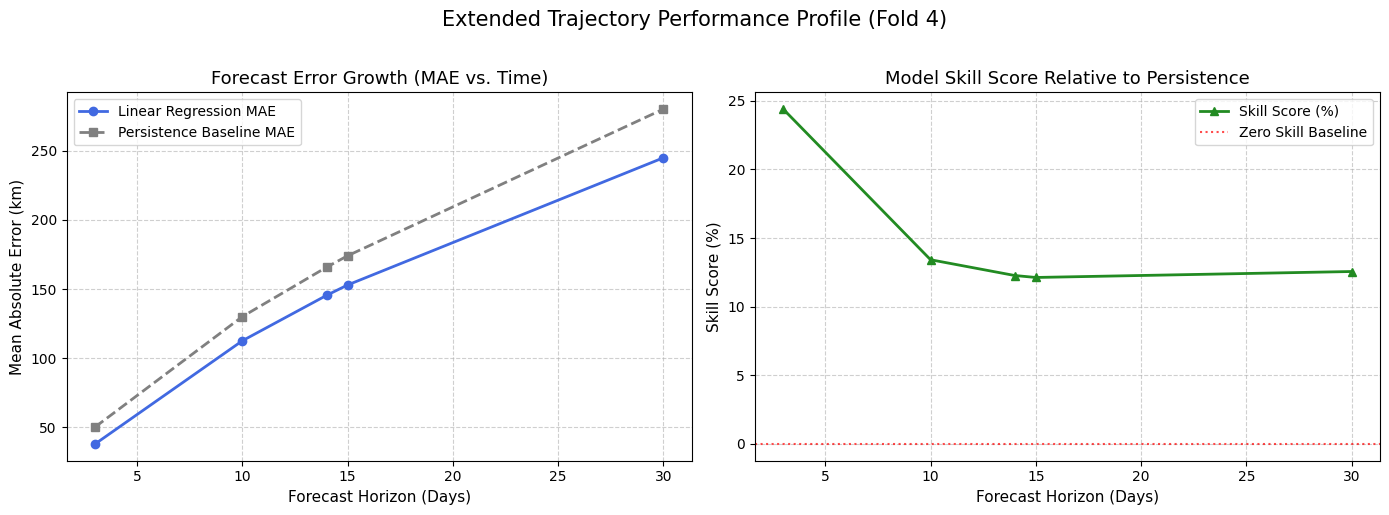

In [11]:
# ==================================================================
# BEST FOLD: EXTENDED HORIZON EVALUATION & PLOTTING
# ==================================================================

# Best fold = highest skill vs persistence, averaged over the 3, 10 and 15-day horizons
fold_skill = cv_eval_summary.groupby('Fold')['Skill_vs_Persistence_%'].mean()
BEST_FOLD = int(fold_skill.idxmax())
BEST_IDX = list(folds).index(BEST_FOLD)       # position of that fold counting from 0 (as used by the map function)
print("Mean skill vs persistence of each fold (%):  " + "  ".join(f"Fold {f}: {s:.2f}" for f, s in fold_skill.items()))
print(f"Best fold: Fold {BEST_FOLD}\n")

# Extract the already-calculated 3-day, 10-day and 15-day results for the best fold (calculated earlier)
fold_base = cv_eval_summary[cv_eval_summary['Fold'] == BEST_FOLD].copy()

# Define new extended horizons in days (14 days and 30 days) and convert to 6-hour steps
target_days = [14, 30]
horizons_steps = [int(days * 24 / 6) for days in target_days]

print(f"Running Extended Horizons (14 & 30 Days) strictly for Fold {BEST_FOLD}...")

# Fit and test ONLY the best fold at the new horizons
fold_new = evaluate_cv_forecasts(fit_cv(horizons_steps, fold_list=[BEST_FOLD], verbose=False), verbose=False)

# Combine base (3, 10 and 15 days) with new extended (14 & 30 days) for the best fold
fold_extended = pd.concat([fold_base, fold_new]).sort_values('Horizon_Days').reset_index(drop=True)

# Display the complete table for the best fold
display(fold_extended)

# ==================================================================
# Plotting MAE and Skill Score Curves
# ==================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: MAE Comparison (Linear regression vs. Persistence)
axes[0].plot(fold_extended['Horizon_Days'], fold_extended['Linear_MAE_km'], marker='o', color='royalblue', linewidth=2, label='Linear Regression MAE')
axes[0].plot(fold_extended['Horizon_Days'], fold_extended['Persistence_MAE_km'], marker='s', color='gray', linestyle='--', linewidth=2, label='Persistence Baseline MAE')
axes[0].set_title('Forecast Error Growth (MAE vs. Time)', fontsize=13)
axes[0].set_xlabel('Forecast Horizon (Days)', fontsize=11)
axes[0].set_ylabel('Mean Absolute Error (km)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

# Plot 2: Skill Score Percentage Progression
axes[1].plot(fold_extended['Horizon_Days'], fold_extended['Skill_vs_Persistence_%'], marker='^', color='forestgreen', linewidth=2, label='Skill Score (%)')
axes[1].axhline(0, color='red', linestyle=':', alpha=0.7, label='Zero Skill Baseline')
axes[1].set_title('Model Skill Score Relative to Persistence', fontsize=13)
axes[1].set_xlabel('Forecast Horizon (Days)', fontsize=11)
axes[1].set_ylabel('Skill Score (%)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

plt.suptitle(f"Extended Trajectory Performance Profile (Fold {BEST_FOLD})", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

In [12]:
# ==================================================================
# STOCHASTIC ENERGY SCORE EVALUATION (Best fold - Linear Regression VS Persistence)
# ==================================================================
# The scores above judge the model's single best forecast. This section judges the whole forecast
# distribution, the same way the energy score section of the Markov chain notebook does:
#     "Start a drifter where a real test drifter started. Take many possible end positions from the
#      model. Does the cloud of simulated end positions look like where the real drifter really was?"
# (the Markov chain samples its transition matrix; the regression samples its bivariate normal error)

N_SIMS = 200                    # simulated end positions per real forecast window
MAX_WINDOWS_PER_QUARTER = 5000  # real test windows used from each quarter, in each fold (lower it to run faster)
SIM_SEED = 42                   # random seed


def score_cloud(sim_lat, sim_lon, y_lat, y_lon, y_cell):
    """Score the cloud of simulated end positions of each window against the real end position."""
    S = sim_lat.shape[1]
    # ENERGY SCORE (km, lower is better) = E|X - y| - 0.5 * E|X - X'|
    #   first term : average distance from a simulated end point X to the real end point y
    #                (accuracy: is the simulation centred on the truth?)
    #   second term: half the average distance between two simulated end points X and X'
    #                (rewards realistic spread, so the model cannot win by predicting one point)
    e_xy = hav(sim_lat, sim_lon, y_lat[:, None], y_lon[:, None]).mean(axis=1)
    pair = hav(sim_lat[:, :, None], sim_lon[:, :, None], sim_lat[:, None, :], sim_lon[:, None, :])
    e_xx = pair.sum(axis=(1, 2)) / (S * (S - 1))     # average over pairs of DIFFERENT simulated drifters
    # Centre of the simulated cloud, how far the real end point is from it, and how spread out
    # the cloud is around its own centre
    c_lat, c_lon = sim_lat.mean(axis=1), sim_lon.mean(axis=1)
    r_sim = hav(sim_lat, sim_lon, c_lat[:, None], c_lon[:, None])
    r_real = hav(y_lat, y_lon, c_lat, c_lon)
    # Calibration: does the real end point fall inside the central 50% / 90% of the cloud as often as it should?
    inside50 = r_real <= np.quantile(r_sim, 0.5, axis=1)
    inside90 = r_real <= np.quantile(r_sim, 0.9, axis=1)
    # Cell-based scores, as in the Markov chain notebook: share of simulated drifters that ended
    # in the cell the real drifter ended in, and whether any of them did
    p_cell = (to_state(sim_lat, sim_lon) == y_cell[:, None]).mean(axis=1)
    return {'es': e_xy - 0.5 * e_xx, 'centroid_err': r_real, 'spread': r_sim.mean(axis=1),
            'inside50': inside50.astype(float), 'inside90': inside90.astype(float),
            'p_cell': p_cell, 'hit': (p_cell > 0).astype(float)}


def summarise_cloud(cloud, dist_persist, mask):
    """Headline numbers for the windows selected by mask. Every window counts equally."""
    tab = {}
    es_p = dist_persist[mask].mean()
    for name, c in cloud.items():
        tab[name] = {
            'Windows evaluated': int(mask.sum()),
            'Energy score (km)': c['es'][mask].mean(),
            'Skill vs persistence (%)': 100 * (1 - c['es'][mask].mean() / es_p),
            'Windows beating persistence (%)': 100 * (c['es'][mask] < dist_persist[mask]).mean(),
            'Centroid error (km)': c['centroid_err'][mask].mean(),
            'Spread of simulated end points (km)': c['spread'][mask].mean(),
            'Real end inside central 50% of cloud (%)': 100 * c['inside50'][mask].mean(),
            'Real end inside central 90% of cloud (%)': 100 * c['inside90'][mask].mean(),
            'Mean prob. on real end cell': c['p_cell'][mask].mean(),
            'Real end cell also simulated (%)': 100 * c['hit'][mask].mean(),
        }
    tab['Persistence'] = {'Windows evaluated': int(mask.sum()), 'Energy score (km)': es_p,
                          'Skill vs persistence (%)': 0.0,
                          'Windows beating persistence (%)': np.nan,
                          'Centroid error (km)': es_p}
    return pd.DataFrame(tab)


def cloud_eval_fold(fold, n_steps):
    """Forecast-cloud evaluation of one fold at one horizon (n_steps): its model, scored on a random sample of its
    test windows."""
    te_ids = folds[fold][1]
    tbl = build_all_windows(n_steps)                                              # windows for this horizon
    te = tbl[np.isin(tbl['id'].to_numpy(), te_ids)].reset_index(drop=True)        # this fold's unseen test windows
    m = next(x for x in cv_models if x['fold'] == fold and x['horizon_steps'] == n_steps)   # the model fitted above
    del tbl

    # ------------------------------------------------------------------
    # Take a random sample of the real test windows
    # ------------------------------------------------------------------
    rng_cloud = np.random.default_rng(SIM_SEED + fold)
    q_te = te['quarter'].to_numpy()
    sel = np.concatenate([rng_cloud.choice(np.flatnonzero(q_te == q),
                                           min(MAX_WINDOWS_PER_QUARTER, int((q_te == q).sum())), replace=False)
                          for q in (1, 2, 3, 4) if (q_te == q).any()])
    ts = te.iloc[np.sort(sel)].reset_index(drop=True)
    n_win = len(ts)
    q_s = ts['quarter'].to_numpy()
    lat0 = ts['lat'].to_numpy(dtype=float)
    lon0 = ts['lon'].to_numpy(dtype=float)
    real_lat, real_lon = end_position(lat0, lon0, ts['dx_km'].to_numpy(dtype=float), ts['dy_km'].to_numpy(dtype=float))
    real_cell = ts['dst_state'].to_numpy()
    print(f"Fold {fold}: real test windows used: {n_win:,}  " + "  ".join(f"Q{q}: {(q_s == q).sum():,}" for q in (1, 2, 3, 4)))

    # ------------------------------------------------------------------
    # Simulate end positions from the two probabilistic models and score them
    # ------------------------------------------------------------------
    mu_s = {'Linear model': design_matrix(ts) @ m['B'],                 # expected displacement from the regression
            'Intercept only': np.tile(m['mu0'], (n_win, 1))}            # the same average displacement for everyone
    cov_s = {'Linear model': m['Sigma'], 'Intercept only': m['Sigma0']}

    cloud = {}
    CHUNK = 200
    for name in mu_s:
        chol = np.linalg.cholesky(cov_s[name])       # turns independent random numbers into errors with covariance Sigma
        parts = []
        for a in range(0, n_win, CHUNK):
            sl = slice(a, a + CHUNK)
            k = len(lat0[sl])
            # displacement = expected displacement + random error, N_SIMS times for every window
            disp = mu_s[name][sl][:, None, :] + rng_cloud.standard_normal((k, N_SIMS, 2)) @ chol.T
            s_lat, s_lon = end_position(lat0[sl][:, None], lon0[sl][:, None], disp[..., 0], disp[..., 1])
            parts.append(score_cloud(s_lat, s_lon, real_lat[sl], real_lon[sl], real_cell[sl]))
        cloud[name] = {key: np.concatenate([p[key] for p in parts]) for key in parts[0]}

    # Persistence: "the drifter stays where it started". A single point has no spread term, so its
    # energy score is just the distance from the start to where the real drifter ended up.
    dist_persist = hav(lat0, lon0, real_lat, real_lon)

    scopes = [(f"Q{q} ({quarter_names[q]})", q_s == q) for q in (1, 2, 3, 4)] + \
             [("OVERALL (all quarters combined)", np.ones(n_win, dtype=bool))]
    return {label: summarise_cloud(cloud, dist_persist, mask) for label, mask in scopes}


# Evaluates the linear model's probabilistic forecast accuracy against the persistence baseline using Energy Scores
def evaluate_best_fold_energy_score(horizons=HORIZONS):
    """
    Energy score of the best fold at each horizon: the regression's forecast cloud VS persistence. Returns the
    summary table (same layout as the Markov chain notebook) and the detailed table of each horizon.
    """
    summary_rows, details = [], {}
    print(f"Running Energy Score Evaluation strictly for Fold {BEST_FOLD}...")
    for n_steps in horizons:
        days = n_steps * 6 / 24
        overall = cloud_eval_fold(BEST_FOLD, n_steps)['OVERALL (all quarters combined)']
        details[days] = overall
        mean_m = overall.loc['Energy score (km)', 'Linear model']
        mean_p = overall.loc['Energy score (km)', 'Persistence']
        summary_rows.append({
            'Fold': BEST_FOLD,
            'Forecast_Days': days,
            'Mean_Energy_Score_Model': mean_m,
            'Mean_Energy_Score_Persistence': mean_p,
            'Skill_vs_Persistence_%': overall.loc['Skill vs persistence (%)', 'Linear model'],
        })
    return pd.DataFrame(summary_rows), details


# Run and display Best fold Energy Score table
best_fold_energy_summary, energy_details = evaluate_best_fold_energy_score()
print(best_fold_energy_summary.to_string(index=False))

# The same cloud, in more detail: distance from the cloud's centre to the real end, how spread out the cloud is, and
# whether the real end falls inside the central 50% / 90% of the cloud as often as it should
pd.set_option('display.width', 250)
for days, tab in energy_details.items():
    print(f"\n--- Fold {BEST_FOLD}, {days:g}-day forecast: all quarters combined ---")
    display(tab.round(4))
print("\n(Energy score and centroid error: lower is better. Spread should be similar in size to the centroid error,")
print(" and the 50% / 90% rows should be close to 50 and 90 if the cloud is well calibrated.)")

Running Energy Score Evaluation strictly for Fold 4...
Fold 4: real test windows used: 20,000  Q1: 5,000  Q2: 5,000  Q3: 5,000  Q4: 5,000
Fold 4: real test windows used: 20,000  Q1: 5,000  Q2: 5,000  Q3: 5,000  Q4: 5,000
Fold 4: real test windows used: 20,000  Q1: 5,000  Q2: 5,000  Q3: 5,000  Q4: 5,000
 Fold  Forecast_Days  Mean_Energy_Score_Model  Mean_Energy_Score_Persistence  Skill_vs_Persistence_%
    4            3.0                28.699894                      50.167702               42.792090
    4           10.0                83.492837                     130.224779               35.885599
    4           15.0               111.932973                     173.526381               35.495126

--- Fold 4, 3-day forecast: all quarters combined ---


,Linear model,Intercept only,Persistence
Windows evaluated,20000.0000,20000.0000,20000.0000
Energy score (km),28.6999,37.4117,50.1677
Skill vs persistence (%),42.7921,25.4266,0.0000
Windows beating persistence (%),82.2800,82.6100,NaN
Centroid error (km),38.1272,50.1619,50.1677
Spread of simulated end points (km),44.7129,57.5932,NaN
Real end inside central 50% of cloud (%),67.8700,65.5800,NaN
Real end inside central 90% of cloud (%),90.8750,91.1450,NaN
Mean prob. on real end cell,0.0084,0.0050,NaN
Real end cell also simulated (%),73.0000,57.7900,NaN



--- Fold 4, 10-day forecast: all quarters combined ---


,Linear model,Intercept only,Persistence
Windows evaluated,20000.0000,20000.0000,20000.0000
Energy score (km),83.4928,95.7697,130.2248
Skill vs persistence (%),35.8856,26.4581,0.0000
Windows beating persistence (%),81.2050,84.8400,NaN
Centroid error (km),113.3052,129.9107,130.2248
Spread of simulated end points (km),125.4491,144.3633,NaN
Real end inside central 50% of cloud (%),62.7950,62.6050,NaN
Real end inside central 90% of cloud (%),90.2350,91.1250,NaN
Mean prob. on real end cell,0.0010,0.0008,NaN
Real end cell also simulated (%),18.1500,14.5700,NaN



--- Fold 4, 15-day forecast: all quarters combined ---


,Linear model,Intercept only,Persistence
Windows evaluated,20000.0000,20000.0000,20000.0000
Energy score (km),111.9330,127.0154,173.5264
Skill vs persistence (%),35.4951,26.8034,0.0000
Windows beating persistence (%),80.7850,84.9800,NaN
Centroid error (km),152.9632,172.7844,173.5264
Spread of simulated end points (km),168.3276,191.2463,NaN
Real end inside central 50% of cloud (%),61.8300,62.1650,NaN
Real end inside central 90% of cloud (%),90.7950,90.9250,NaN
Mean prob. on real end cell,0.0006,0.0004,NaN
Real end cell also simulated (%),10.2700,8.2700,NaN



(Energy score and centroid error: lower is better. Spread should be similar in size to the centroid error,
 and the 50% / 90% rows should be close to 50 and 90 if the cloud is well calibrated.)


## Understanding and Analysing the Forecast Cloud Evaluation

### What does it do?
For each historical test window:
1. It takes the starting position and features of a real drifter.
2. It draws 200 random samples from the model's bivariate normal error distribution (using the covariance matrix $\Sigma$).
3. It maps these displacements back into final latitude/longitude coordinates to form a "cloud" of simulated final positions.
4. It evaluates the cloud against the real, observed final position using spatial metrics:
   * **Energy Score (ES):** Measures both the distance from the simulated points to the true destination (accuracy) and penalizes the cloud if its points are either too clustered or too spread out (calibration). Higher skill indicates a more physically realistic distribution.
   * **Centroid Error:** The physical distance (in km) between the center of the simulated cloud and the actual final location.
   * **Spread:** The average internal radius of the simulated cloud, representing the model's uncertainty.
   * **Calibration (Central 50% / 90%):** Verifies if the true position falls within the inner 50% or 90% of the simulated cloud's radius. A perfectly calibrated model should see close to 50% and 90% respectively.

/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


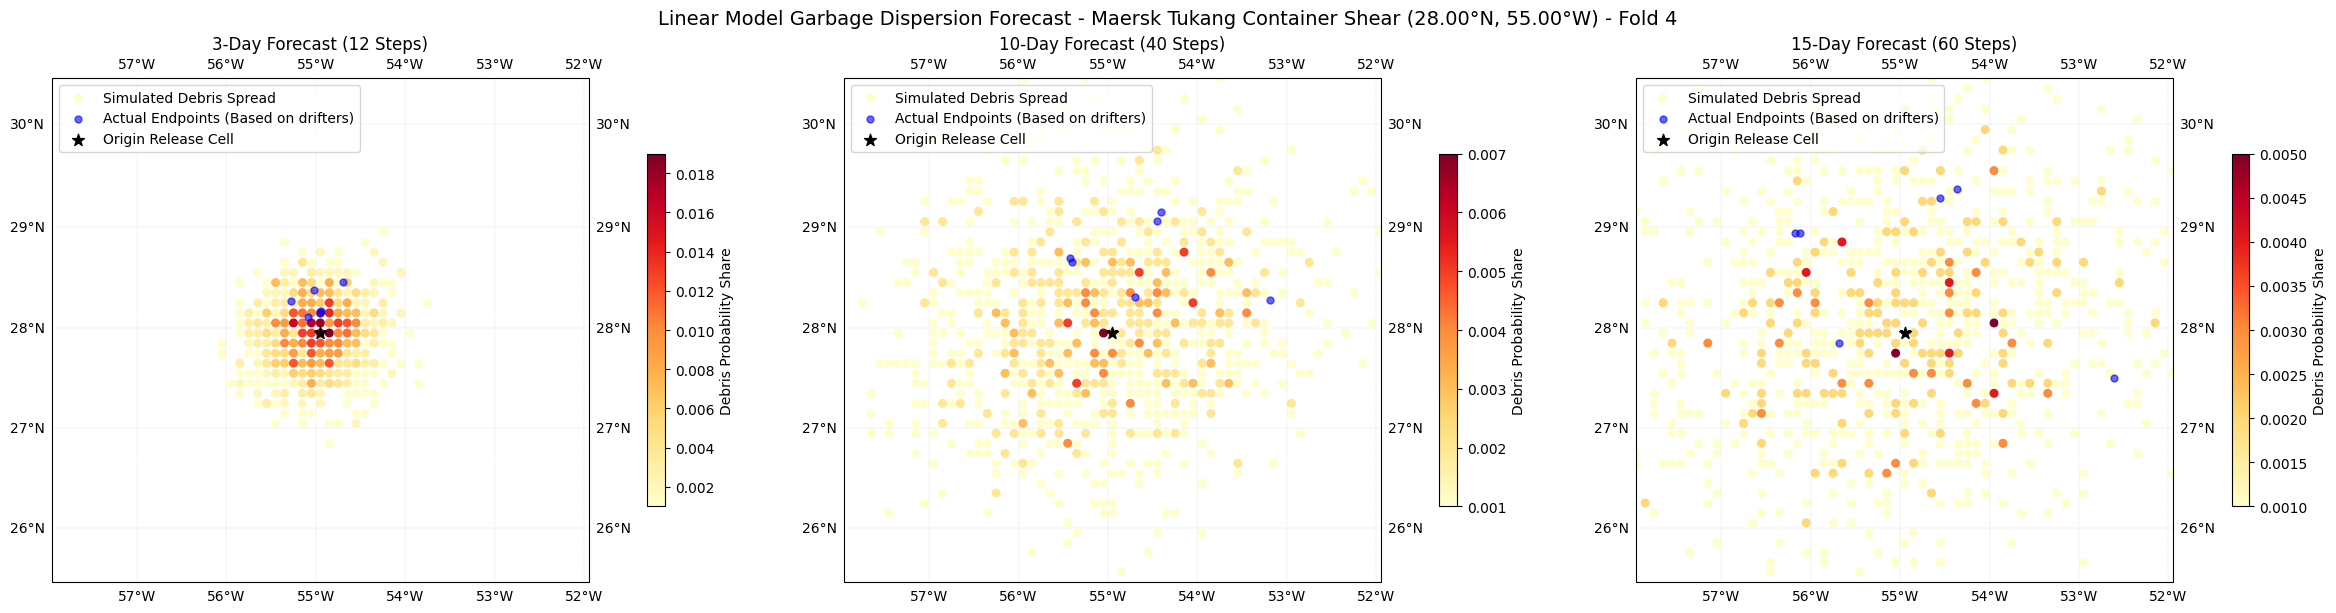

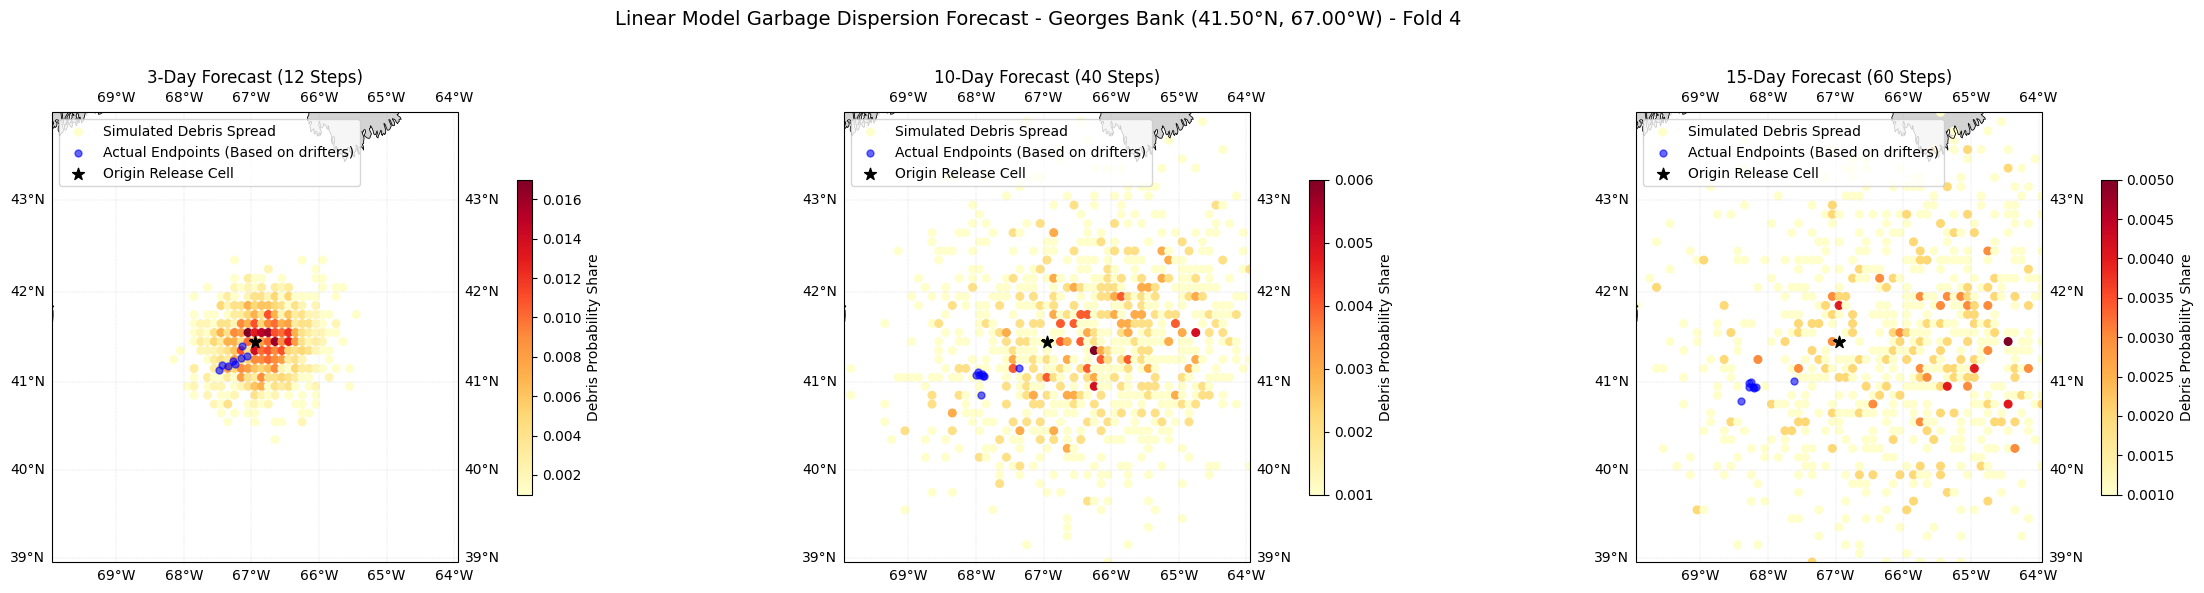

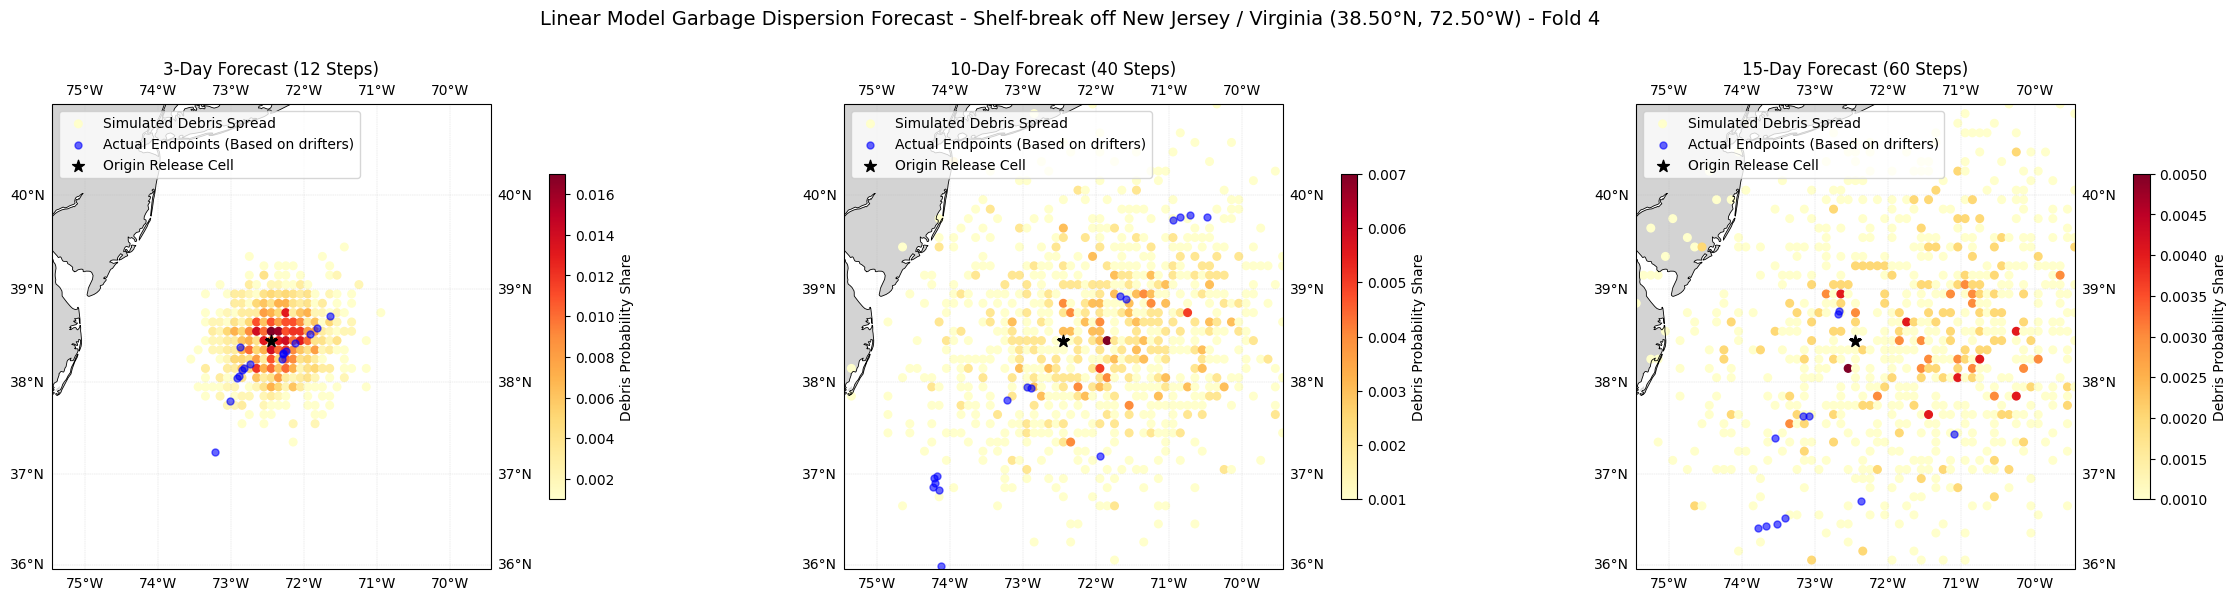

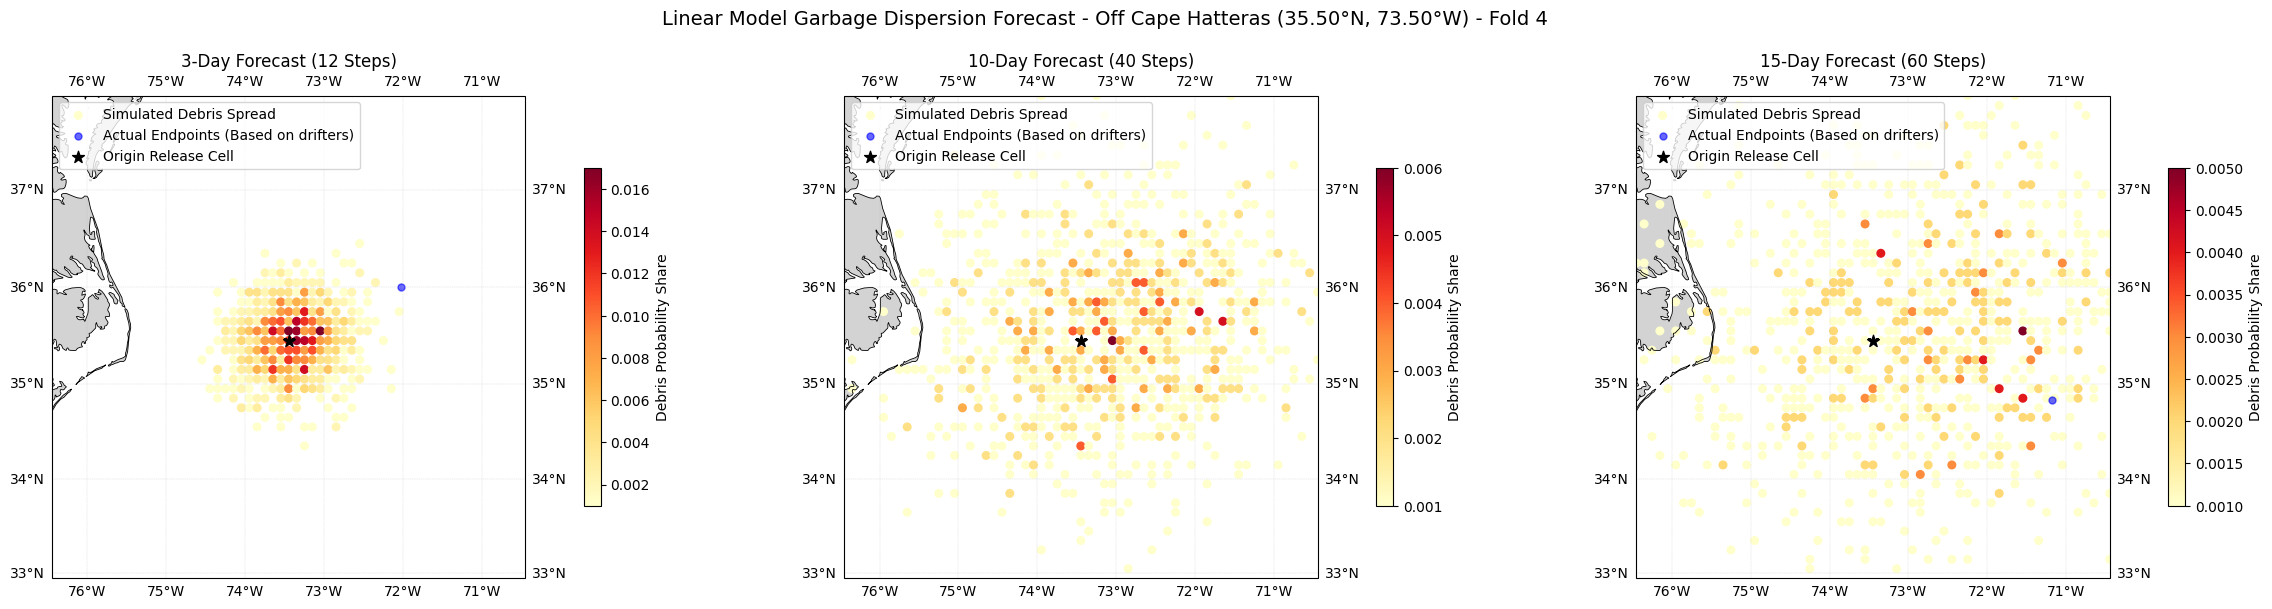

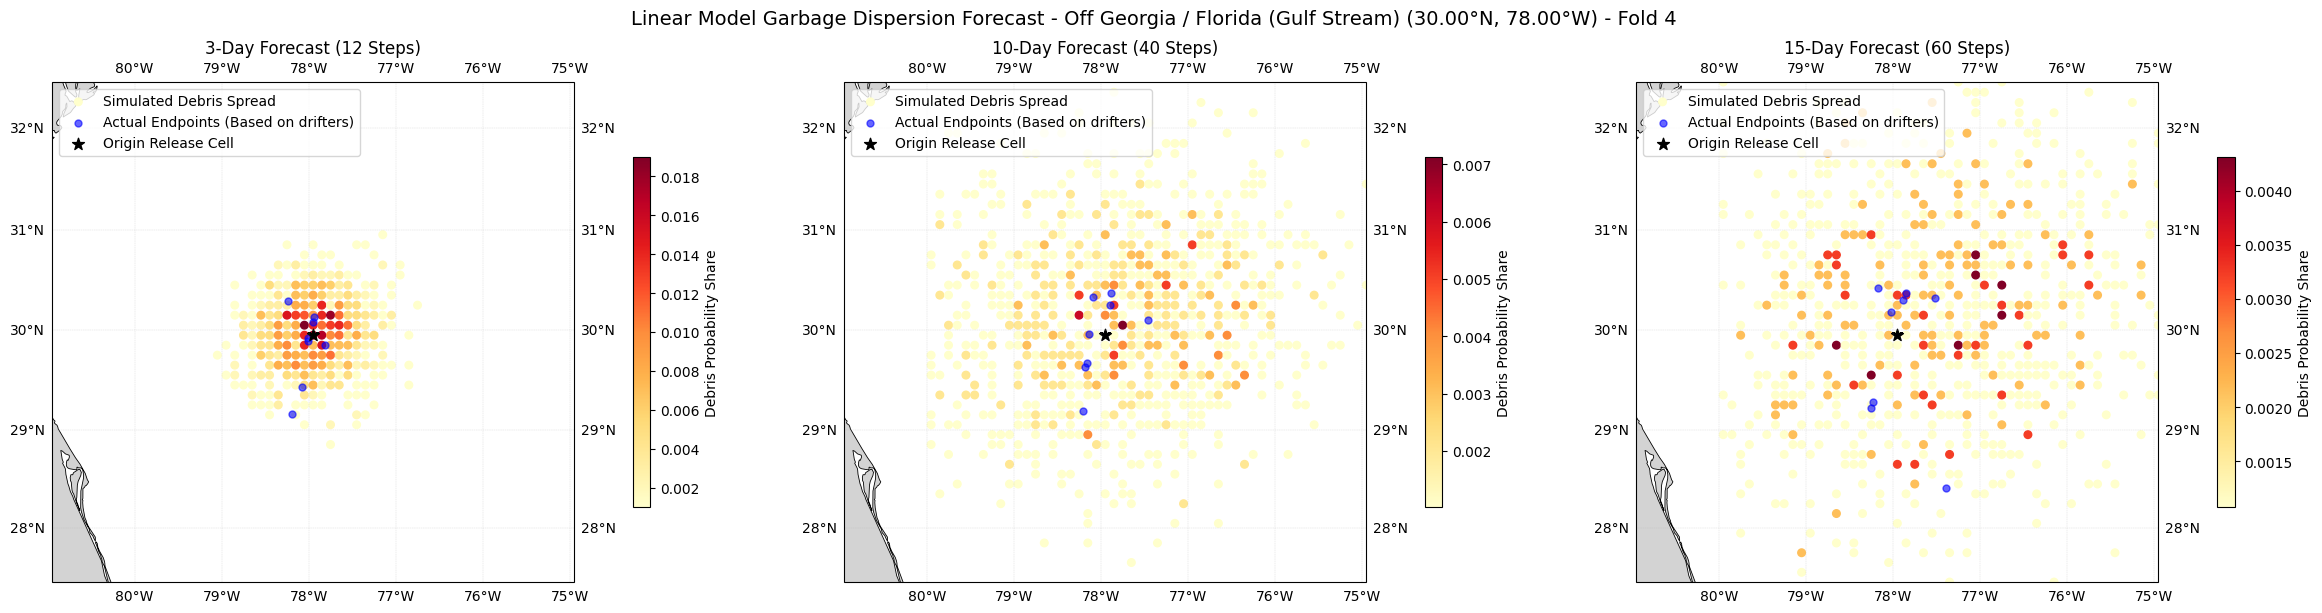

In [13]:
# ==================================================================
# FORECAST DISPERSION MAP OF THE LINEAR MODEL (single origin coordinate)
# ==================================================================
# The linear-model counterpart of forecast_garbage_patch_fate (Markov chain). It releases
# n_sims simulated drifters at one origin and plots where they could be after each forecast horizon.
#
# How the regression produces the cloud (compare: the Markov chain samples from its matrix):
#   1. The fold's fitted model turns the origin's features (lat, lon, season, ...) into an expected
#      displacement (km east, km north) over the horizon.
#   2. A random error is added to it, drawn from the fitted bivariate normal (covariance Sigma).
#   3. The displacement is converted back to latitude / longitude, and every simulated end
#      position is put in its 0.1 x 0.1 degree grid cell, as in the Markov chain map.
# One regression is fitted per horizon (a 3-day forecast is its own model, not the 6-hour model
# run 12 times), so the models are looked up for each horizon in turn.


_linear_model_cache = {}

def get_linear_model(fold, n_steps):
    """Retrieve or fit the linear regression model for one fold and horizon."""
    key = (fold, n_steps, tuple(FEATURES))
    if key in _linear_model_cache:
        return _linear_model_cache[key]

    model = None
    if n_steps == ALL_TBL_STEPS:
        model = fold_models[fold]
    else:
        for m in globals().get('cv_models', []):
            if m['fold'] == fold and m['horizon_steps'] == n_steps:
                model = m
                break

    if model is None:
        tbl = build_all_windows(n_steps)
        model = fit_linear(tbl[np.isin(tbl['id'].to_numpy(), folds[fold][0])])

    _linear_model_cache[key] = model
    return model


def origin_features(lat, lon, extra_features=None):
    """Build the feature vector [1, lat, lon, ...] for a single release coordinate."""
    values = [1.0]
    for name in FEATURES:
        if name == 'lat':
            values.append(lat)
        elif name == 'lon':
            values.append(lon)
        elif extra_features and name in extra_features:
            values.append(float(extra_features[name]))
        else:
            values.append(0.0)  # default to 0 (at rest) for lagged displacements
    return np.array(values)


def forecast_garbage_patch_fate_linear(lat, lon, fold_idx=3, n_sims=1000, extra_features=None, place=None):
    """
    Simulates and visualizes probabilistic debris dispersion using the Linear Regression model
    from any coordinate, for any fold index, across 3-day, 10-day, and 15-day windows
    (formatted to match Model 1's forecast_garbage_patch_fate plots).
    """
    # Snap to grid cell center to align origin & actual test drifters with Model 1
    cell = int(to_state([lat], [lon])[0])
    latA, lonA = state_to_latlon(cell)

    fold = list(folds)[fold_idx]          # e.g. fold_idx=3 -> Fold 4
    te_ids = folds[fold][1]               # held-out test drifter IDs for this fold
    x = origin_features(latA, lonA, extra_features)

    rng = np.random.default_rng(42)

    horizons = [
        (12, "3-Day Forecast (12 Steps)"),
        (40, "10-Day Forecast (40 Steps)"),
        (60, "15-Day Forecast (60 Steps)")
    ]

    fig, axes = plt.subplots(
        1, len(horizons),
        figsize=(8 * len(horizons), 6),
        subplot_kw={'projection': ccrs.Mercator()}
    )

    for ax, (n_steps, title_label) in zip(axes, horizons):
        model = get_linear_model(fold, n_steps)
        mu = x @ model['B']                               # expected displacement (dx_km, dy_km)
        chol = np.linalg.cholesky(model['Sigma'])         # bivariate normal error covariance

        # Monte Carlo draws around predicted displacement -> convert to end lat/lon
        disp = mu + rng.standard_normal((n_sims, 2)) @ chol.T
        s_lat, s_lon = end_position(latA, lonA, disp[:, 0], disp[:, 1])

        # Keep particles inside the study domain and bin into 0.1-degree grid cells
        inside = (s_lat >= LAT_MIN) & (s_lat < LAT_MAX) & (s_lon >= LON_MIN) & (s_lon < LON_MAX)
        u, cnts = np.unique(to_state(s_lat[inside], s_lon[inside]), return_counts=True)
        lat_u, lon_u = state_to_latlon(u)

        # Extract actual held-out test endpoints starting from this cell (matching Model 1)
        tbl = build_all_windows(n_steps)
        actual_subset = tbl[np.isin(tbl['id'].to_numpy(), te_ids) & (tbl['src_state'] == cell)]
        if len(actual_subset) > 0:
            lat_actual, lon_actual = end_position(
                actual_subset['lat'].to_numpy(),
                actual_subset['lon'].to_numpy(),
                actual_subset['dx_km'].to_numpy(),
                actual_subset['dy_km'].to_numpy()
            )
        else:
            lat_actual, lon_actual = [], []
        del tbl

        # Zoom extent matching Model 1
        ax.set_extent([lonA - 3, lonA + 3, latA - 2.5, latA + 2.5], crs=ccrs.PlateCarree())

        # Plot simulated debris spread
        sc = ax.scatter(
            lon_u, lat_u, c=cnts / cnts.sum(), s=30, cmap='YlOrRd',
            transform=ccrs.PlateCarree(), label='Simulated Debris Spread'
        )

        # Plot actual recorded test endpoints
        if len(lat_actual) > 0:
            ax.scatter(
                lon_actual, lat_actual, marker='o', c='blue', s=25, alpha=0.6,
                transform=ccrs.PlateCarree(), label='Actual Endpoints (Based on drifters)'
            )

        # Plot origin release cell
        ax.scatter(
            lonA, latA, marker='*', c='black', s=80,
            transform=ccrs.PlateCarree(), label='Origin Release Cell'
        )

        # Geographic features & gridlines
        ax.add_feature(cfeature.LAND, facecolor='lightgray')
        ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
        ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5, linestyle='--')

        ax.set_title(title_label, fontsize=12)
        plt.colorbar(sc, ax=ax, shrink=0.7, pad=0.08, label='Debris Probability Share')
        ax.legend(loc='upper left')

    place_txt = f"{place} " if place else ""
    plt.suptitle(
        f"Linear Model Garbage Dispersion Forecast - {place_txt}({lat:.2f}°N, {abs(lon):.2f}°W) - Fold {fold}\n",
        fontsize=14
    )
    plt.tight_layout()
    plt.show()


# Run visual dispersion maps for Fold 4 (fold_idx=3) across the same release points
map_extra = {'dx_lag1': 0.0, 'dy_lag1': 0.0}

for lat_, lon_, place_ in [
    (28.0, -55.0, "Maersk Tukang Container Shear"),
    (41.5, -67.0, "Georges Bank"),
    (38.5, -72.5, "Shelf-break off New Jersey / Virginia"),
    (35.5, -73.5, "Off Cape Hatteras"),
    (30.0, -78.0, "Off Georgia / Florida (Gulf Stream)")
]:
    forecast_garbage_patch_fate_linear(
        lat=lat_, lon=lon_, fold_idx=BEST_IDX, extra_features=map_extra, place=place_
    )

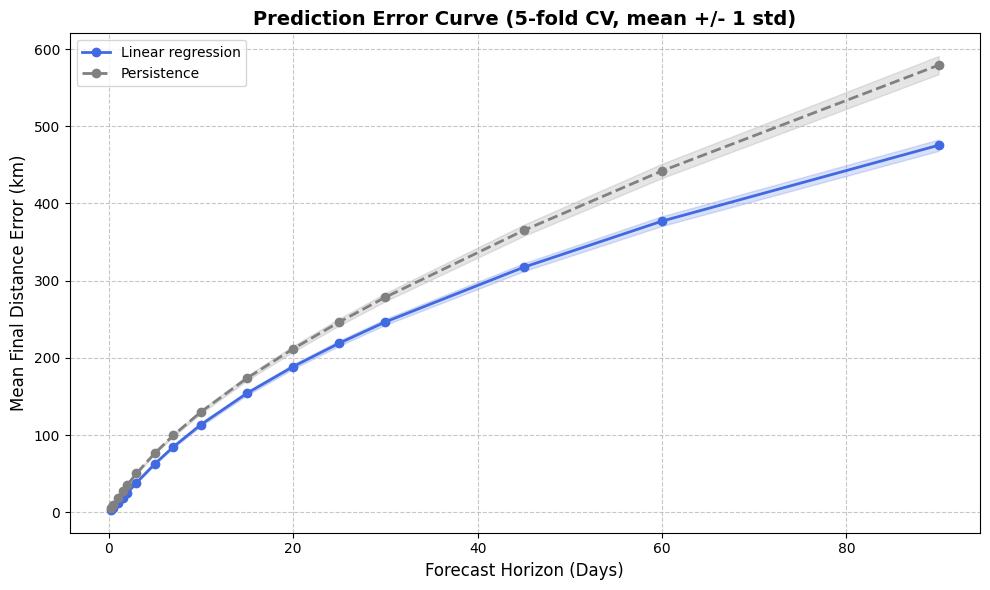

In [14]:
# ------------------------------------------------------------------
# Plotting time horizon (Days) vs error, with the spread across folds
# ------------------------------------------------------------------
# Define the range of forecast horizons (in days)
horizons_days = [0.25, 0.5, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 25.0, 30.0, 45.0, 60.0, 90.0]

# Steps = days * 4. Each horizon refits the model on every fold.
cv_curve = evaluate_cv_forecasts(fit_cv([int(d * 4) for d in horizons_days], verbose=False), verbose=False)

grp = cv_curve.groupby('Horizon_Days')
mean_, std_ = grp.mean(numeric_only=True), grp.std(numeric_only=True)

plt.figure(figsize=(10, 6))
for col, lab, colr, ls in [('Linear_MAE_km', 'Linear regression', 'royalblue', '-'),
                           ('Persistence_MAE_km', 'Persistence', 'gray', '--')]:
    plt.plot(mean_.index, mean_[col], marker='o', color=colr, linestyle=ls, linewidth=2, label=lab)
    plt.fill_between(mean_.index, mean_[col] - std_[col], mean_[col] + std_[col], color=colr, alpha=0.2)
plt.title(f'Prediction Error Curve ({K}-fold CV, mean +/- 1 std)', fontsize=14, fontweight='bold')
plt.xlabel('Forecast Horizon (Days)', fontsize=12)
plt.ylabel('Mean Final Distance Error (km)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()